**Earth Temperature Detective (ETD)**

In [1]:
import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook", palette="viridis")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 11

In [2]:
data = pd.read_csv("Dataset.csv")
data.head(20)

,sample,DISPH,PS,QV10M,QV2M,SLP,T10M,T2M,TO3,TOX,...,Var_TS,Var_U10M,Var_U2M,Var_U50M,Var_V10M,Var_V2M,Var_V50M,lon,lat,time
0,0,0.238891,60031.530,0.005706,0.005991,100060.250,277.18683,276.60226,238.33524,0.005116,...,57.870880,4.586557,2.585245,6.894381,2.550646,1.405136,4.027510,97.500,32.0,2020-10-01
1,1,0.000000,100766.490,0.005688,0.005792,100766.540,280.79047,280.82944,291.67267,0.006260,...,0.167852,24.509860,16.866290,33.389720,27.764912,19.356096,38.347390,-97.500,-49.5,2020-12-01
2,2,0.330922,93412.540,0.013392,0.014056,101096.610,299.54288,299.50824,264.09630,0.005667,...,48.496580,2.760649,1.476768,5.609246,1.783565,0.777172,4.485272,-46.250,-16.0,2023-02-01
3,3,0.000000,100848.370,0.007267,0.007438,100848.430,284.70578,284.77100,280.98746,0.006030,...,0.556682,16.366392,11.175678,21.852505,41.582070,28.757576,57.607204,-162.500,-49.0,2022-01-01
4,4,0.000000,100779.310,0.004875,0.004923,100779.310,277.73890,277.73166,287.54684,0.006174,...,0.242952,18.196148,12.996481,25.952484,20.092468,14.396327,28.926039,117.500,76.0,2022-08-01
5,5,7.759033,96831.516,0.004286,0.004432,101317.440,277.42993,277.29877,389.56207,0.008358,...,52.946007,3.030907,0.074976,9.932297,3.889640,0.121284,13.236287,-76.875,48.5,2021-04-01
6,6,0.000000,100971.650,0.018741,0.019325,100971.586,301.29434,301.38287,253.58904,0.005442,...,0.077238,3.187040,2.504147,3.759211,7.230028,5.476369,8.705918,41.875,-12.5,2021-01-01
7,7,0.000000,101108.920,0.016696,0.017221,101108.880,299.25815,299.31525,247.55212,0.005313,...,0.058049,1.155168,0.835736,1.476617,1.109036,0.804901,1.390229,-95.625,-5.0,2022-04-01
8,8,0.028870,101145.380,0.000105,0.000099,102484.390,234.30928,233.26128,388.16943,0.008322,...,42.515854,3.083937,1.399527,6.395971,8.064517,4.163660,16.170020,133.125,70.5,2023-01-01
9,9,0.000000,101612.460,0.000481,0.000495,101612.350,249.00943,249.14270,419.82500,0.009006,...,26.476500,18.459936,12.884297,23.808826,26.889494,18.687222,34.662277,-93.750,59.5,2021-02-01


In [3]:
data.shape

(500000, 52)

In [4]:
data.columns

Index(['sample', 'DISPH', 'PS', 'QV10M', 'QV2M', 'SLP', 'T10M', 'T2M', 'TO3',
       'TOX', 'TQI', 'TQL', 'TQV', 'TROPPB', 'TROPPT', 'TROPPV', 'TROPQ',
       'TROPT', 'TS', 'U10M', 'U2M', 'U50M', 'V10M', 'V2M', 'V50M',
       'Var_DISPH', 'Var_PS', 'Var_QV10M', 'Var_QV2M', 'Var_SLP', 'Var_T10M',
       'Var_T2M', 'Var_TO3', 'Var_TOX', 'Var_TQI', 'Var_TQL', 'Var_TQV',
       'Var_TROPPB', 'Var_TROPPT', 'Var_TROPPV', 'Var_TROPQ', 'Var_TROPT',
       'Var_TS', 'Var_U10M', 'Var_U2M', 'Var_U50M', 'Var_V10M', 'Var_V2M',
       'Var_V50M', 'lon', 'lat', 'time'],
      dtype='object')

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 52 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   sample      500000 non-null  int64  
 1   DISPH       500000 non-null  float64
 2   PS          500000 non-null  float64
 3   QV10M       500000 non-null  float64
 4   QV2M        500000 non-null  float64
 5   SLP         500000 non-null  float64
 6   T10M        500000 non-null  float64
 7   T2M         500000 non-null  float64
 8   TO3         500000 non-null  float64
 9   TOX         500000 non-null  float64
 10  TQI         500000 non-null  float64
 11  TQL         500000 non-null  float64
 12  TQV         500000 non-null  float64
 13  TROPPB      500000 non-null  float64
 14  TROPPT      500000 non-null  float64
 15  TROPPV      499230 non-null  float64
 16  TROPQ       500000 non-null  float64
 17  TROPT       500000 non-null  float64
 18  TS          500000 non-null  float64
 19  U1

In [6]:
data.dtypes

sample          int64
DISPH         float64
PS            float64
QV10M         float64
QV2M          float64
SLP           float64
T10M          float64
T2M           float64
TO3           float64
TOX           float64
TQI           float64
TQL           float64
TQV           float64
TROPPB        float64
TROPPT        float64
TROPPV        float64
TROPQ         float64
TROPT         float64
TS            float64
U10M          float64
U2M           float64
U50M          float64
V10M          float64
V2M           float64
V50M          float64
Var_DISPH     float64
Var_PS        float64
Var_QV10M     float64
Var_QV2M      float64
Var_SLP       float64
Var_T10M      float64
Var_T2M       float64
Var_TO3       float64
Var_TOX       float64
Var_TQI       float64
Var_TQL       float64
Var_TQV       float64
Var_TROPPB    float64
Var_TROPPT    float64
Var_TROPPV    float64
Var_TROPQ     float64
Var_TROPT     float64
Var_TS        float64
Var_U10M      float64
Var_U2M       float64
Var_U50M  

In [7]:
data.describe()

,sample,DISPH,PS,QV10M,QV2M,SLP,T10M,T2M,TO3,TOX,...,Var_TROPT,Var_TS,Var_U10M,Var_U2M,Var_U50M,Var_V10M,Var_V2M,Var_V50M,lon,lat
count,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,...,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,5.000000e+05
mean,249999.500000,0.717297,96621.319764,0.007584,0.007814,100811.248886,278.739879,278.623696,290.653123,0.006237,...,26.745212,16.702962,14.870881,10.082941,20.804427,16.059050,10.935735,22.523711,-0.336373,-3.296000e-03
std,144337.711635,3.009510,9592.559808,0.006183,0.006389,1216.579856,21.463505,21.725053,48.589317,0.001042,...,19.755597,25.806126,13.598107,9.560197,17.797677,15.051671,10.605244,19.834962,103.876865,5.211292e+01
min,0.000000,0.000000,50659.656000,0.000005,0.000004,96047.430000,205.667420,204.258820,107.038530,0.002311,...,0.873260,0.000479,0.033688,0.000003,0.224512,0.038930,0.000004,0.077823,-180.000000,-9.000000e+01
25%,124999.750000,0.000000,97754.455000,0.002303,0.002354,100429.956250,268.264575,268.156145,263.291665,0.005650,...,9.214226,0.073033,4.205254,2.563822,6.883551,4.018689,2.527161,6.427711,-90.000000,-4.500000e+01
50%,249999.500000,0.000000,100742.830000,0.005881,0.006032,101127.330000,283.831535,283.800690,281.197680,0.006034,...,23.612983,0.743605,10.701166,7.040692,15.987689,10.468066,6.748705,16.121705,-0.625000,-1.797510e-13
75%,374999.250000,0.002405,101436.882500,0.012842,0.013314,101617.855000,296.876448,296.916938,310.807055,0.006669,...,39.651547,26.192184,21.711706,15.096414,29.888415,24.894892,17.477412,34.223169,90.000000,4.500000e+01
max,499999.000000,23.078125,103837.850000,0.027050,0.027535,103788.730000,314.348050,314.426670,527.023200,0.011303,...,209.316180,245.582230,167.585630,110.568200,229.336010,111.180550,75.540810,152.731340,179.375000,9.000000e+01


In [8]:
data.isna().sum()

sample          0
DISPH           0
PS              0
QV10M           0
QV2M            0
SLP             0
T10M            0
T2M             0
TO3             0
TOX             0
TQI             0
TQL             0
TQV             0
TROPPB          0
TROPPT          0
TROPPV        770
TROPQ           0
TROPT           0
TS              0
U10M            0
U2M             0
U50M            0
V10M            0
V2M             0
V50M            0
Var_DISPH       0
Var_PS          0
Var_QV10M       0
Var_QV2M        0
Var_SLP         0
Var_T10M        0
Var_T2M         0
Var_TO3         0
Var_TOX         0
Var_TQI         0
Var_TQL         0
Var_TQV         0
Var_TROPPB      0
Var_TROPPT      0
Var_TROPPV    770
Var_TROPQ       0
Var_TROPT       0
Var_TS          0
Var_U10M        0
Var_U2M         0
Var_U50M        0
Var_V10M        0
Var_V2M         0
Var_V50M        0
lon             0
lat             0
time            0
dtype: int64

In [9]:
data['time'] = pd.to_datetime(data['time'],errors='coerce')
print(data['time'].min())

2020-09-01 00:00:00


In [10]:
data['time'] = pd.to_datetime(data['time'],errors='coerce')
print(data['time'].max())

2023-09-01 00:00:00


In [11]:
data["time"] = pd.to_datetime(data["time"], errors="coerce")
for col in ["T2M", "T10M", "TS", "lon", "lat"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(subset=["time", "lon", "lat", "T2M", "T10M", "TS"]).copy()

In [12]:
for col in ["T2M", "T10M", "TS"]:
    data[col + "_C"] = data[col] - 273.15

In [13]:
data = data.sort_values("time").reset_index(drop=True)
data["year"] = data["time"].dt.year
data["month"] = data["time"].dt.month
data["month_name"] = data["time"].dt.strftime("%b")
data["time_period"] = data["time"].dt.to_period("M").astype(str)


In [14]:
data.head()

,sample,DISPH,PS,QV10M,QV2M,SLP,T10M,T2M,TO3,TOX,...,lon,lat,time,T2M_C,T10M_C,TS_C,year,month,month_name,time_period
0,231996,3.306772,100212.016,0.007306,0.007461,101637.630,284.87006,284.62097,280.16586,0.006012,...,40.625,57.5,2020-09-01,11.47097,11.72006,11.37533,2020,9,Sep,2020-09
1,395826,0.000000,61941.684,0.000018,0.000016,100056.020,215.47102,214.00569,160.06975,0.003438,...,44.375,-82.0,2020-09-01,-59.14431,-57.67898,-63.71767,2020,9,Sep,2020-09
2,395824,0.000729,100514.660,0.021075,0.021586,100519.700,302.92877,302.94543,272.40036,0.005846,...,48.750,13.5,2020-09-01,29.79543,29.77877,30.09356,2020,9,Sep,2020-09
3,251307,0.000000,101426.060,0.010507,0.010824,101426.055,291.25320,291.32657,269.09283,0.005775,...,-84.375,-8.0,2020-09-01,18.17657,18.10320,18.77343,2020,9,Sep,2020-09
4,395800,2.829579,81305.620,0.003797,0.003798,101101.640,294.23303,293.35480,271.67987,0.005830,...,-118.125,36.0,2020-09-01,20.20480,21.08303,19.34527,2020,9,Sep,2020-09


In [15]:
data.shape

(500000, 59)

In [16]:
data["time"].nunique()

37

In [17]:
data[["lon", "lat"]].drop_duplicates().shape[0]

190554

In [18]:
quality = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing": data.isna().sum(),
    "missing_pct": (data.isna().mean() * 100).round(2),
    "n_unique": data.nunique()
})
display(quality.sort_values("missing_pct", ascending=False).head(20))

monthly_n = data.groupby("time_period").size().rename("n_samples")
display(monthly_n.to_frame().T)

,dtype,missing,missing_pct,n_unique
TROPPV,float64,770,0.15,486840
Var_TROPPV,float64,770,0.15,493385
Var_T10M,float64,0,0.00,495503
Var_TO3,float64,0,0.00,495292
Var_TOX,float64,0,0.00,440164
Var_TQI,float64,0,0.00,445149
Var_TQL,float64,0,0.00,458755
Var_TQV,float64,0,0.00,480774
Var_TROPPB,float64,0,0.00,480736
Var_TROPPT,float64,0,0.00,494403


time_period,2020-09,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,...,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09
n_samples,13533,13363,13627,13568,13621,13552,13538,13488,13589,13542,...,13563,13556,13509,13392,13472,13467,13360,13533,13485,13564


,count,mean,std,min,25%,50%,75%,max
T2M_C,500000.0,5.47,21.73,-68.89,-4.99,10.65,23.77,41.28
T10M_C,500000.0,5.59,21.46,-67.48,-4.89,10.68,23.73,41.20
TS_C,500000.0,5.83,22.71,-76.38,-4.38,11.30,24.60,43.33


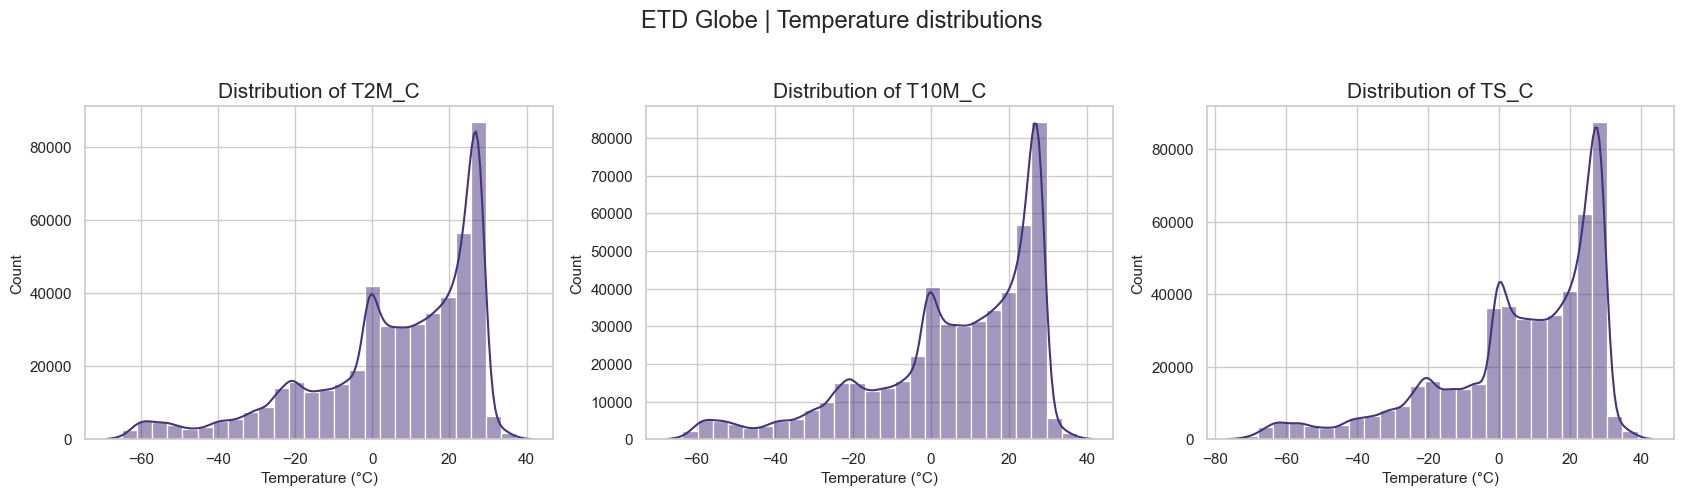

In [19]:
temp_cols = ["T2M_C", "T10M_C", "TS_C"]
display(data[temp_cols].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col in zip(axes, temp_cols):
    sns.histplot(data[col], kde=True, bins=28, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Temperature (°C)")
plt.suptitle("ETD Globe | Temperature distributions", y=1.03, fontsize=17)
plt.tight_layout()
plt.show()

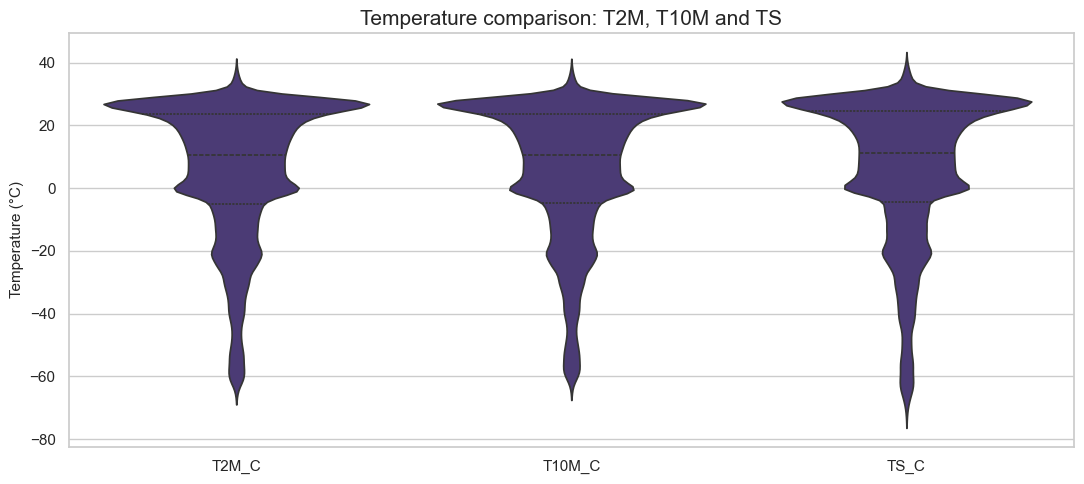

In [20]:
long_temp = data.melt(
    id_vars=["time", "lon", "lat"],
    value_vars=temp_cols,
    var_name="variable",
    value_name="temperature_c"
)
plt.figure(figsize=(11, 5))
sns.violinplot(data=long_temp, x="variable", y="temperature_c", inner="quartile", cut=0)
plt.title("Temperature comparison: T2M, T10M and TS")
plt.xlabel("")
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

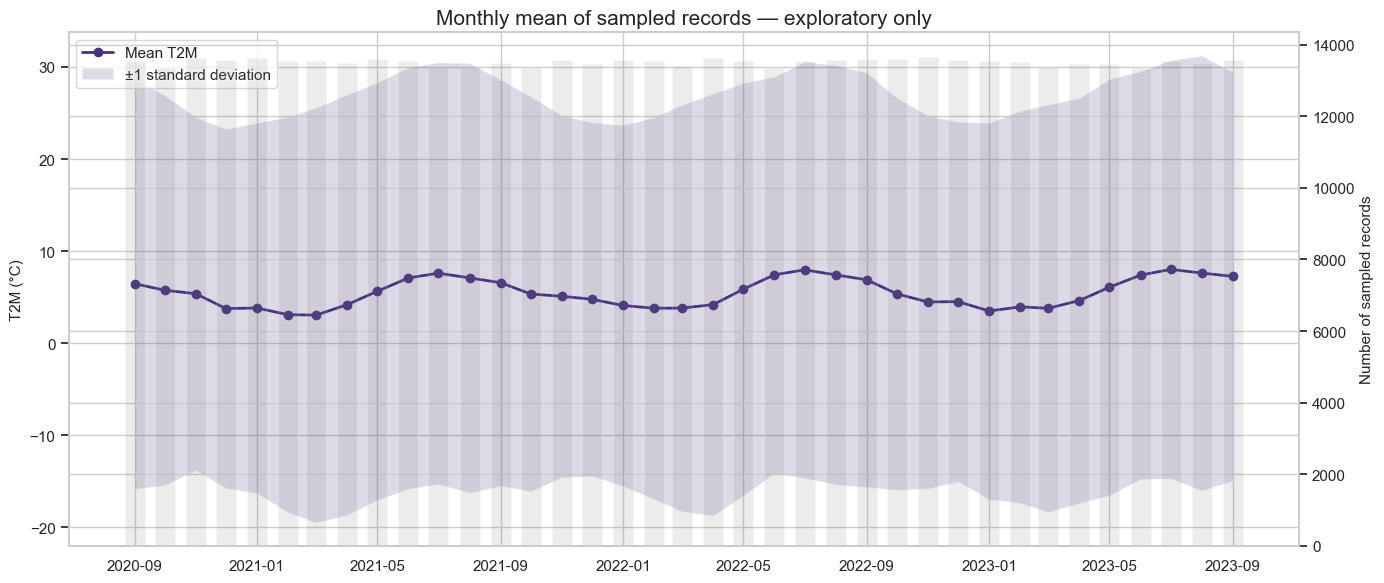

In [21]:
monthly = (
    data.groupby("time_period")
      .agg(T2M_mean_C=("T2M_C", "mean"),
           T2M_median_C=("T2M_C", "median"),
           T2M_std_C=("T2M_C", "std"),
           n_samples=("T2M_C", "size"))
      .reset_index()
)
monthly["time"] = pd.to_datetime(monthly["time_period"] + "-01")

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(monthly["time"], monthly["T2M_mean_C"], marker="o", linewidth=2, label="Mean T2M")
ax1.fill_between(monthly["time"],
                 monthly["T2M_mean_C"] - monthly["T2M_std_C"],
                 monthly["T2M_mean_C"] + monthly["T2M_std_C"],
                 alpha=0.18, label="±1 standard deviation")
ax1.set_ylabel("T2M (°C)")
ax1.set_title("Monthly mean of sampled records — exploratory only")
ax1.legend(loc="upper left")
ax2 = ax1.twinx()
ax2.bar(monthly["time"], monthly["n_samples"], alpha=0.15, width=20, color="gray")
ax2.set_ylabel("Number of sampled records")
plt.tight_layout()
plt.show()

fig = px.line(monthly, x="time", y=["T2M_mean_C", "T2M_median_C"],
              markers=True, title="Monthly sampled-record temperature summary (°C)")
fig.update_layout(yaxis_title="Temperature (°C)", xaxis_title="Month")
fig.show()

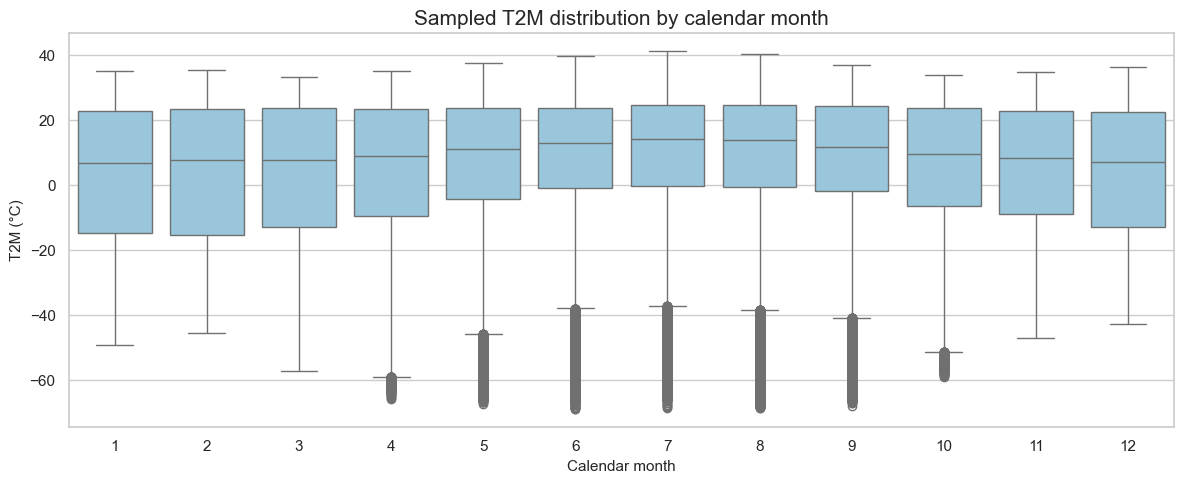

In [22]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=data, x="month", y="T2M_C", color="#8ecae6")
plt.title("Sampled T2M distribution by calendar month")
plt.xlabel("Calendar month")
plt.ylabel("T2M (°C)")
plt.tight_layout()
plt.show()

*What is the spatial and temporal coverage of the dataset, and are the records suitable for monthly temperature analysis?*

In [23]:
analysis_data = data.copy()

required_columns = ["time", "lat", "lon", "T2M_C"]
missing_columns = [col for col in required_columns if col not in analysis_data.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

analysis_data["time"] = pd.to_datetime(analysis_data["time"], errors="coerce")

for col in ["lat", "lon", "T2M_C"]:
    analysis_data[col] = pd.to_numeric(analysis_data[col], errors="coerce")

analysis_data = analysis_data.dropna(
    subset=["time", "lat", "lon", "T2M_C"]
).copy()

# Standardize longitude to the -180 to 180 range.
analysis_data["lon"] = ((analysis_data["lon"] + 180) % 360) - 180

analysis_data["year"] = analysis_data["time"].dt.year
analysis_data["month"] = analysis_data["time"].dt.month
analysis_data["time_period"] = analysis_data["time"].dt.to_period("M").astype(str)

# Approximate area weights for a regular latitude-longitude grid.
analysis_data["area_weight"] = np.cos(
    np.deg2rad(analysis_data["lat"])
).clip(lower=0)

coverage = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of unique months",
        "Number of unique latitude-longitude points",
        "First observation",
        "Last observation",
        "Missing T2M values after cleaning"
    ],
    "Value": [
        len(analysis_data),
        analysis_data["time_period"].nunique(),
        analysis_data[["lat", "lon"]].drop_duplicates().shape[0],
        analysis_data["time"].min(),
        analysis_data["time"].max(),
        analysis_data["T2M_C"].isna().sum()
    ]
})

display(coverage)
display(
    analysis_data.groupby("time_period")
    .agg(
        records=("T2M_C", "size"),
        grid_points=("lon", "count")
    )
    .head(10)
)

,Metric,Value
0,Number of records,500000
1,Number of unique months,37
2,Number of unique latitude-longitude points,190554
3,First observation,2020-09-01 00:00:00
4,Last observation,2023-09-01 00:00:00
5,Missing T2M values after cleaning,0


,records,grid_points
time_period,,
2020-09,13533,13533
2020-10,13363,13363
2020-11,13627,13627
2020-12,13568,13568
2021-01,13621,13621
2021-02,13552,13552
2021-03,13538,13538
2021-04,13488,13488
2021-05,13589,13589


*How do temperature patterns differ across Greenland, the Sahara Desert, and the Amazon region?*

In [24]:
regions = {
    "Greenland": {
        "lat_min": 58, "lat_max": 84,
        "lon_min": -75, "lon_max": -10
    },
    "Sahara Desert": {
        "lat_min": 15, "lat_max": 33,
        "lon_min": -17, "lon_max": 35
    },
    "Amazon": {
        "lat_min": -20, "lat_max": 5,
        "lon_min": -80, "lon_max": -45
    }
}

def select_region(df, region_name):
    bounds = regions[region_name]
    return df.loc[
        df["lat"].between(bounds["lat_min"], bounds["lat_max"]) &
        df["lon"].between(bounds["lon_min"], bounds["lon_max"])
    ].copy()

region_coverage = []

for region_name in regions:
    region_df = select_region(analysis_data, region_name)
    region_coverage.append({
        "Region": region_name,
        "Records": len(region_df),
        "Unique_grid_points": region_df[["lat", "lon"]].drop_duplicates().shape[0],
        "Available_months": region_df["time_period"].nunique()
    })

region_coverage = pd.DataFrame(region_coverage)
display(region_coverage)

,Region,Records,Unique_grid_points,Available_months
0,Greenland,13364,5127,37
1,Sahara Desert,7597,2860,37
2,Amazon,6772,2649,37


*What was the monthly mean 2-meter air temperature in the global sample and in each selected region?*

In [25]:
def weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    valid = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    if valid.sum() == 0:
        return np.nan
    return np.average(values[valid], weights=weights[valid])

def calculate_monthly_temperature(df):
    rows = []
    for period, group in df.groupby("time_period", sort=True):
        rows.append({
            "time_period": period,
            "T2M_mean_C": weighted_mean(
                group["T2M_C"], group["area_weight"]
            ),
            "T2M_median_C": group["T2M_C"].median(),
            "T2M_std_C": group["T2M_C"].std(),
            "T2M_min_C": group["T2M_C"].min(),
            "T2M_max_C": group["T2M_C"].max(),
            "n_records": len(group),
            "n_grid_points": group[["lat", "lon"]].drop_duplicates().shape[0]
        })

    result = pd.DataFrame(rows)
    result["time"] = pd.to_datetime(result["time_period"] + "-01")
    result["year"] = result["time"].dt.year
    result["month"] = result["time"].dt.month
    return result.sort_values("time").reset_index(drop=True)

global_monthly = calculate_monthly_temperature(analysis_data)

region_monthly = {
    name: calculate_monthly_temperature(select_region(analysis_data, name))
    for name in regions
}

display(global_monthly.head())
display(region_monthly["Greenland"].head())

,time_period,T2M_mean_C,T2M_median_C,T2M_std_C,T2M_min_C,T2M_max_C,n_records,n_grid_points,time,year,month
0,2020-09,15.629498,11.264860,22.292716,-65.00382,36.50030,13533,13533,2020-09-01,2020,9
1,2020-10,14.920942,9.838000,21.163483,-57.62340,33.56713,13363,13363,2020-10-01,2020,10
2,2020-11,13.923698,8.308700,19.184669,-42.05814,34.75048,13627,13627,2020-11-01,2020,11
3,2020-12,12.480996,6.192055,19.503379,-42.57735,33.54687,13568,13568,2020-12-01,2020,12
4,2021-01,12.524386,6.642300,20.107639,-48.94660,35.03723,13621,13621,2021-01-01,2021,1


,time_period,T2M_mean_C,T2M_median_C,T2M_std_C,T2M_min_C,T2M_max_C,n_records,n_grid_points,time,year,month
0,2020-09,-4.329030,-5.552160,12.409815,-30.07700,12.08267,347,347,2020-09-01,2020,9
1,2020-10,-5.150761,-5.970680,11.028372,-27.91340,9.67160,357,357,2020-10-01,2020,10
2,2020-11,-10.632151,-16.190695,13.241720,-37.48690,9.45327,400,400,2020-11-01,2020,11
3,2020-12,-12.979248,-19.552650,12.624217,-36.05184,8.14193,341,341,2020-12-01,2020,12
4,2021-01,-13.509101,-19.451770,12.320789,-38.72982,7.55227,361,361,2021-01-01,2021,1


*How did the monthly mean temperature in the available global sample vary during the study period?*

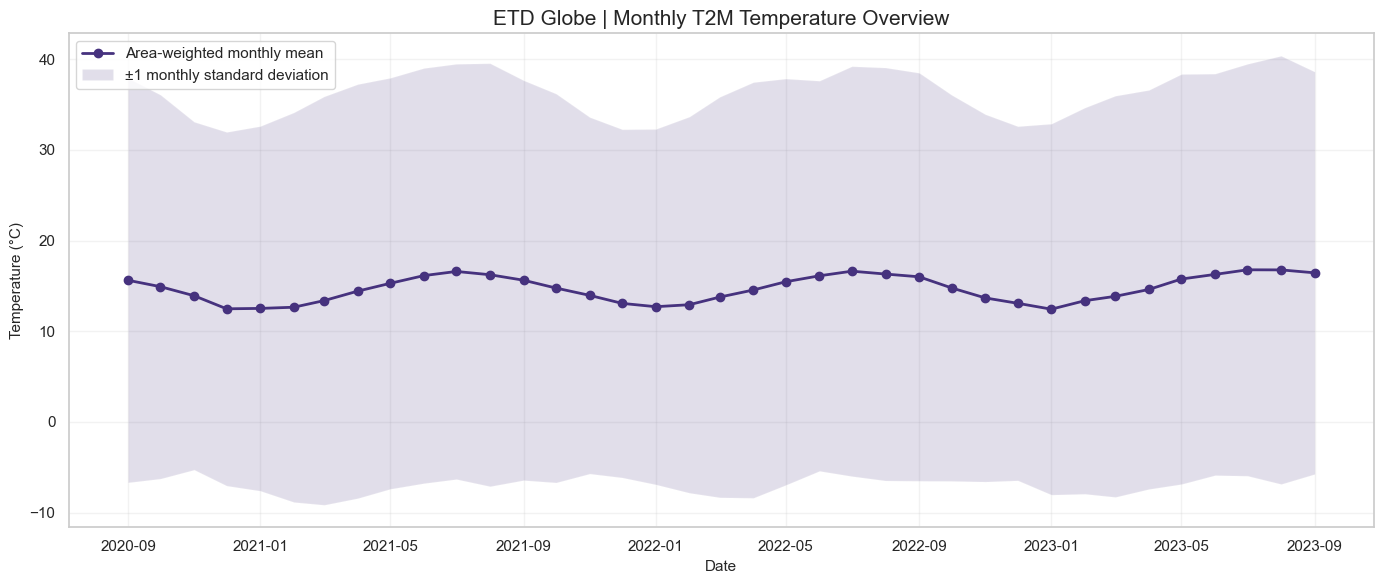

In [26]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    global_monthly["time"],
    global_monthly["T2M_mean_C"],
    marker="o",
    linewidth=2,
    label="Area-weighted monthly mean"
)

ax.fill_between(
    global_monthly["time"],
    global_monthly["T2M_mean_C"] - global_monthly["T2M_std_C"],
    global_monthly["T2M_mean_C"] + global_monthly["T2M_std_C"],
    alpha=0.16,
    label="±1 monthly standard deviation"
)

ax.set_title("ETD Globe | Monthly T2M Temperature Overview")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig = px.line(
    global_monthly,
    x="time",
    y=["T2M_mean_C", "T2M_median_C"],
    markers=True,
    title="Monthly Mean and Median T2M"
)
fig.update_layout(
    template="plotly_dark",
    xaxis_title="Month",
    yaxis_title="Temperature (°C)",
    hovermode="x unified"
)
fig.show()

*How did the annual average temperature and the range of monthly averages change from year to year?*

In [27]:
yearly_global = (
    global_monthly.groupby("year")
    .agg(
        Mean_Temperature_C=("T2M_mean_C", "mean"),
        Median_of_Monthly_Medians_C=("T2M_median_C", "median"),
        Lowest_Monthly_Mean_C=("T2M_mean_C", "min"),
        Highest_Monthly_Mean_C=("T2M_mean_C", "max"),
        Monthly_Variability_C=("T2M_mean_C", "std"),
        Available_Months=("time_period", "nunique")
    )
    .reset_index()
)

yearly_global["Change_from_previous_year_C"] = (
    yearly_global["Mean_Temperature_C"].diff()
)

display(yearly_global.round(2))

fig = px.bar(
    yearly_global,
    x="year",
    y="Mean_Temperature_C",
    color="Mean_Temperature_C",
    color_continuous_scale="Viridis",
    text_auto=".2f",
    title="Annual Mean Temperature in the Available Global Sample"
)
fig.update_layout(
    template="plotly_dark",
    xaxis_title="Year",
    yaxis_title="Mean temperature (°C)"
)
fig.show()

,year,Mean_Temperature_C,Median_of_Monthly_Medians_C,Lowest_Monthly_Mean_C,Highest_Monthly_Mean_C,Monthly_Variability_C,Available_Months,Change_from_previous_year_C
0,2020,14.24,9.07,12.48,15.63,1.36,4,NaN
1,2021,14.56,9.03,12.52,16.60,1.44,12,0.32
2,2022,14.67,9.56,12.71,16.63,1.42,12,0.11
3,2023,15.15,11.84,12.44,16.78,1.62,9,0.48


*How did the mean temperature differ between winter, spring, summer, and autumn across the available years?*

In [28]:
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}
season_order = ["Winter", "Spring", "Summer", "Autumn"]

seasonal_source = global_monthly.copy()
seasonal_source["season"] = seasonal_source["month"].map(season_map)
seasonal_source["season_year"] = (
    seasonal_source["year"] +
    (seasonal_source["month"] == 12).astype(int)
)

seasonal_global = (
    seasonal_source.groupby(["season_year", "season"])
    .agg(
        Mean_Temperature_C=("T2M_mean_C", "mean"),
        Min_Monthly_Mean_C=("T2M_mean_C", "min"),
        Max_Monthly_Mean_C=("T2M_mean_C", "max"),
        Available_Months=("time_period", "nunique")
    )
    .reset_index()
)

seasonal_global["season"] = pd.Categorical(
    seasonal_global["season"],
    categories=season_order,
    ordered=True
)
seasonal_global = seasonal_global.sort_values(
    ["season_year", "season"]
)

display(seasonal_global.round(2))

fig = px.line(
    seasonal_global,
    x="season_year",
    y="Mean_Temperature_C",
    color="season",
    markers=True,
    title="Global Seasonal Temperature Across Years"
)
fig.update_layout(
    template="plotly_dark",
    xaxis_title="Season year",
    yaxis_title="Mean temperature (°C)"
)
fig.show()

seasonal_pivot = seasonal_global.pivot(
    index="season_year",
    columns="season",
    values="Mean_Temperature_C"
)
display(seasonal_pivot.round(2))

,season_year,season,Mean_Temperature_C,Min_Monthly_Mean_C,Max_Monthly_Mean_C,Available_Months
0,2020,Autumn,14.82,13.92,15.63,3
4,2021,Winter,12.55,12.48,12.66,3
2,2021,Spring,14.37,13.39,15.29,3
3,2021,Summer,16.33,16.14,16.60,3
1,2021,Autumn,14.79,13.96,15.64,3
8,2022,Winter,12.91,12.71,13.08,3
6,2022,Spring,14.60,13.77,15.47,3
7,2022,Summer,16.36,16.12,16.63,3
5,2022,Autumn,14.83,13.68,16.01,3
12,2023,Winter,12.97,12.44,13.38,3


season,Winter,Spring,Summer,Autumn
season_year,,,,
2020,NaN,NaN,NaN,14.82
2021,12.55,14.37,16.33,14.79
2022,12.91,14.60,16.36,14.83
2023,12.97,14.75,16.61,16.45


*Which of the three selected regions had the highest average temperature, the widest observed range, and the greatest month-to-month variability?*

In [29]:
region_summary_rows = []

for name in regions:
    selected = select_region(analysis_data, name)
    monthly = region_monthly[name]

    region_summary_rows.append({
        "Region": name,
        "Mean_T2M_C": weighted_mean(
            selected["T2M_C"], selected["area_weight"]
        ) if len(selected) else np.nan,
        "Median_T2M_C": selected["T2M_C"].median(),
        "Std_T2M_C": selected["T2M_C"].std(),
        "Minimum_T2M_C": selected["T2M_C"].min(),
        "Maximum_T2M_C": selected["T2M_C"].max(),
        "Observed_Range_C": (
            selected["T2M_C"].max() - selected["T2M_C"].min()
            if len(selected) else np.nan
        ),
        "Monthly_Mean_Std_C": monthly["T2M_mean_C"].std(),
        "Records": len(selected),
        "Grid_Points": selected[["lat", "lon"]].drop_duplicates().shape[0],
        "Available_Months": monthly["time_period"].nunique()
    })

region_summary = pd.DataFrame(region_summary_rows)
display(
    region_summary.style
    .format(precision=2)
    .background_gradient(
        subset=["Mean_T2M_C", "Monthly_Mean_Std_C"],
        cmap="YlOrRd"
    )
)

fig = px.bar(
    region_summary,
    x="Region",
    y="Mean_T2M_C",
    color="Mean_T2M_C",
    color_continuous_scale="YlOrRd",
    text_auto=".2f",
    title="Average T2M by Selected Region"
)
fig.update_layout(
    template="plotly_dark",
    yaxis_title="Temperature (°C)"
)
fig.show()

,Region,Mean_T2M_C,Median_T2M_C,Std_T2M_C,Minimum_T2M_C,Maximum_T2M_C,Observed_Range_C,Monthly_Mean_Std_C,Records,Grid_Points,Available_Months
0,Greenland,-6.88,-8.06,13.20,-43.71,14.61,58.32,6.98,13364,5127,37
1,Sahara Desert,24.67,25.01,7.38,4.58,40.31,35.73,6.28,7597,2860,37
2,Amazon,24.29,25.41,4.82,2.39,33.57,31.18,1.02,6772,2649,37


*When did Greenland, the Sahara, and the Amazon experience their warmer and cooler months, and how different were their monthly temperature patterns?*

In [30]:
region_comparison = pd.concat(
    [
        monthly_df.assign(Region=name)
        for name, monthly_df in region_monthly.items()
    ],
    ignore_index=True
)

fig = px.line(
    region_comparison,
    x="time",
    y="T2M_mean_C",
    color="Region",
    markers=True,
    title="Monthly Temperature Comparison | Greenland, Sahara, Amazon"
)
fig.update_layout(
    template="plotly_dark",
    height=580,
    hovermode="x unified",
    xaxis_title="Date",
    yaxis_title="Temperature (°C)"
)
fig.show()

display(
    region_comparison.pivot(
        index="time_period",
        columns="Region",
        values="T2M_mean_C"
    ).round(2)
)

Region,Amazon,Greenland,Sahara Desert
time_period,,,
2020-09,26.19,-4.33,29.94
2020-10,25.89,-5.15,25.89
2020-11,25.02,-10.63,19.90
2020-12,25.07,-12.98,17.09
2021-01,24.80,-13.51,15.72
2021-02,24.68,-14.13,17.21
2021-03,23.82,-16.54,20.48
2021-04,23.88,-9.53,25.24
2021-05,23.72,-4.45,30.06


*Did the annual temperature averages in Greenland, the Sahara, and the Amazon move in the same direction during the study period?*

In [31]:
regional_yearly_rows = []

for name, monthly_df in region_monthly.items():
    yearly = (
        monthly_df.groupby("year")
        .agg(
            Mean_Temperature_C=("T2M_mean_C", "mean"),
            Lowest_Monthly_Mean_C=("T2M_mean_C", "min"),
            Highest_Monthly_Mean_C=("T2M_mean_C", "max"),
            Available_Months=("time_period", "nunique")
        )
        .reset_index()
    )
    yearly["Region"] = name
    regional_yearly_rows.append(yearly)

regional_yearly = pd.concat(
    regional_yearly_rows, ignore_index=True
)

display(
    regional_yearly.sort_values(["Region", "year"]).round(2)
)

fig = px.bar(
    regional_yearly,
    x="year",
    y="Mean_Temperature_C",
    color="Region",
    barmode="group",
    title="Annual Mean Temperature by Region"
)
fig.update_layout(
    template="plotly_dark",
    yaxis_title="Temperature (°C)"
)
fig.show()

,year,Mean_Temperature_C,Lowest_Monthly_Mean_C,Highest_Monthly_Mean_C,Available_Months,Region
8,2020,25.54,25.02,26.19,4,Amazon
9,2021,24.34,23.14,25.57,12,Amazon
10,2022,23.82,21.99,25.68,12,Amazon
11,2023,24.28,23.43,26.57,9,Amazon
0,2020,-8.27,-12.98,-4.33,4,Greenland
1,2021,-6.69,-16.54,3.75,12,Greenland
2,2022,-7.07,-18.67,2.25,12,Greenland
3,2023,-6.32,-17.78,3.92,9,Greenland
4,2020,23.21,17.09,29.94,4,Sahara Desert
5,2021,24.82,15.67,32.52,12,Sahara Desert


*How do the seasonal temperature cycles differ between Greenland and the Sahara, and what quarterly pattern appears in the Amazon region?*

In [32]:
regional_seasonal_tables = []

for name, monthly_df in region_monthly.items():
    temp = monthly_df.copy()

    if name in ["Greenland", "Sahara Desert"]:
        temp["season"] = temp["month"].map(season_map)
        temp["season_year"] = (
            temp["year"] + (temp["month"] == 12).astype(int)
        )
        grouped = (
            temp.groupby(["season_year", "season"])
            .agg(
                Mean_Temperature_C=("T2M_mean_C", "mean"),
                Available_Months=("time_period", "nunique")
            )
            .reset_index()
        )
        grouped["Period_Type"] = "Meteorological season"
    else:
        temp["quarter"] = ((temp["month"] - 1) // 3) + 1
        grouped = (
            temp.groupby(["year", "quarter"])
            .agg(
                Mean_Temperature_C=("T2M_mean_C", "mean"),
                Available_Months=("time_period", "nunique")
            )
            .reset_index()
            .rename(columns={"year": "season_year"})
        )
        grouped["season"] = "Quarter " + grouped["quarter"].astype(str)
        grouped["Period_Type"] = "Calendar quarter"

    grouped["Region"] = name
    regional_seasonal_tables.append(grouped)

regional_seasonal = pd.concat(
    regional_seasonal_tables, ignore_index=True
)

display(
    regional_seasonal.sort_values(
        ["Region", "season_year"]
    ).round(2)
)

fig = px.line(
    regional_seasonal,
    x="season_year",
    y="Mean_Temperature_C",
    color="season",
    facet_row="Region",
    markers=True,
    title="Regional Seasonal and Quarterly Temperature Patterns"
)
fig.update_layout(
    template="plotly_dark",
    height=850,
    yaxis_title="Temperature (°C)"
)
fig.show()

,season_year,season,Mean_Temperature_C,Available_Months,Period_Type,Region,quarter
26,2020,Quarter 3,26.19,1,Calendar quarter,Amazon,3.0
27,2020,Quarter 4,25.33,3,Calendar quarter,Amazon,4.0
28,2021,Quarter 1,24.43,3,Calendar quarter,Amazon,1.0
29,2021,Quarter 2,23.94,3,Calendar quarter,Amazon,2.0
30,2021,Quarter 3,24.38,3,Calendar quarter,Amazon,3.0
31,2021,Quarter 4,24.63,3,Calendar quarter,Amazon,4.0
32,2022,Quarter 1,24.06,3,Calendar quarter,Amazon,1.0
33,2022,Quarter 2,22.82,3,Calendar quarter,Amazon,2.0
34,2022,Quarter 3,23.91,3,Calendar quarter,Amazon,3.0
35,2022,Quarter 4,24.48,3,Calendar quarter,Amazon,4.0


*Which months were warmer or colder than the average for the same calendar month during the available study period?*

In [33]:
def calculate_monthly_anomalies(monthly_df):
    result = monthly_df.copy()

    baseline = result.groupby("month")["T2M_mean_C"].mean()
    baseline_std = result.groupby("month")["T2M_mean_C"].std()

    result["Monthly_Baseline_C"] = result["month"].map(baseline)
    result["Temperature_Anomaly_C"] = (
        result["T2M_mean_C"] - result["Monthly_Baseline_C"]
    )
    result["Anomaly_Z_Score"] = (
        result["Temperature_Anomaly_C"] /
        result["month"].map(baseline_std).replace(0, np.nan)
    )
    result["Anomaly_Type"] = np.select(
        [
            result["Temperature_Anomaly_C"] > 0,
            result["Temperature_Anomaly_C"] < 0
        ],
        [
            "Warmer than period baseline",
            "Colder than period baseline"
        ],
        default="Equal to period baseline"
    )
    return result

global_anomalies = calculate_monthly_anomalies(global_monthly)

display(
    global_anomalies[
        [
            "time_period", "T2M_mean_C",
            "Monthly_Baseline_C",
            "Temperature_Anomaly_C",
            "Anomaly_Z_Score", "Anomaly_Type"
        ]
    ].round(2)
)

fig = px.bar(
    global_anomalies,
    x="time",
    y="Temperature_Anomaly_C",
    color="Temperature_Anomaly_C",
    color_continuous_scale="RdBu_r",
    title="Monthly Temperature Anomalies in the Global Sample"
)
fig.add_hline(y=0, line_dash="dash", line_color="white")
fig.update_layout(
    template="plotly_dark",
    xaxis_title="Date",
    yaxis_title="Temperature anomaly (°C)"
)
fig.show()

global_extremes = (
    global_anomalies.assign(
        Absolute_Anomaly_C=lambda x: x["Temperature_Anomaly_C"].abs()
    )
    .nlargest(10, "Absolute_Anomaly_C")
)
display(
    global_extremes[
        ["time_period", "T2M_mean_C",
         "Temperature_Anomaly_C", "Anomaly_Type"]
    ].round(2)
)

,time_period,T2M_mean_C,Monthly_Baseline_C,Temperature_Anomaly_C,Anomaly_Z_Score,Anomaly_Type
0,2020-09,15.63,15.93,-0.30,-0.78,Colder than period baseline
1,2020-10,14.92,14.82,0.10,1.15,Warmer than period baseline
2,2020-11,13.92,13.86,0.07,0.44,Warmer than period baseline
3,2020-12,12.48,12.88,-0.40,-1.15,Colder than period baseline
4,2021-01,12.52,12.56,-0.03,-0.25,Colder than period baseline
5,2021-02,12.66,12.99,-0.33,-0.91,Colder than period baseline
6,2021-03,13.39,13.67,-0.29,-1.14,Colder than period baseline
7,2021-04,14.43,14.53,-0.10,-1.10,Colder than period baseline
8,2021-05,15.29,15.51,-0.22,-0.90,Colder than period baseline
9,2021-06,16.14,16.18,-0.04,-0.45,Colder than period baseline


,time_period,T2M_mean_C,Temperature_Anomaly_C,Anomaly_Type
36,2023-09,16.45,0.52,Warmer than period baseline
3,2020-12,12.48,-0.40,Colder than period baseline
29,2023-02,13.38,0.39,Warmer than period baseline
5,2021-02,12.66,-0.33,Colder than period baseline
35,2023-08,16.77,0.33,Warmer than period baseline
0,2020-09,15.63,-0.30,Colder than period baseline
12,2021-09,15.64,-0.30,Colder than period baseline
6,2021-03,13.39,-0.29,Colder than period baseline
32,2023-05,15.77,0.26,Warmer than period baseline
8,2021-05,15.29,-0.22,Colder than period baseline


*Was the fitted linear trend positive or negative in each region during the available period, and how strong was the linear relationship?*

In [34]:
trend_rows = []

for name, monthly_df in {
    "Global sample": global_monthly,
    **region_monthly
}.items():

    temp = monthly_df.dropna(subset=["T2M_mean_C"]).copy()

    if len(temp) < 3:
        continue

    temp["time_index"] = np.arange(len(temp))
    result = stats.linregress(
        temp["time_index"], temp["T2M_mean_C"]
    )

    trend_rows.append({
        "Region": name,
        "Monthly_Slope_C_per_month": result.slope,
        "Estimated_Slope_C_per_year": result.slope * 12,
        "R_squared": result.rvalue ** 2,
        "P_value": result.pvalue,
        "Months_Used": len(temp),
        "Direction": (
            "Increasing" if result.slope > 0
            else "Decreasing" if result.slope < 0
            else "No linear change"
        )
    })

trend_summary = pd.DataFrame(trend_rows)
display(trend_summary.round(4))

fig = go.Figure()

for name, monthly_df in {
    "Global sample": global_monthly,
    **region_monthly
}.items():
    temp = monthly_df.dropna(subset=["T2M_mean_C"])
    fig.add_trace(go.Scatter(
        x=temp["time"],
        y=temp["T2M_mean_C"],
        mode="lines+markers",
        name=name
    ))

fig.update_layout(
    template="plotly_dark",
    title="Monthly Temperature Series by Region",
    xaxis_title="Date",
    yaxis_title="Temperature (°C)",
    hovermode="x unified",
    height=580
)
fig.show()

,Region,Monthly_Slope_C_per_month,Estimated_Slope_C_per_year,R_squared,P_value,Months_Used,Direction
0,Global sample,0.0382,0.4585,0.0824,0.0850,37,Increasing
1,Greenland,0.1200,1.4406,0.0346,0.2700,37,Increasing
2,Sahara Desert,0.1173,1.4082,0.0409,0.2298,37,Increasing
3,Amazon,-0.0190,-0.2277,0.0408,0.2305,37,Decreasing


*Which selected region showed the largest variation in monthly mean temperature during the study period?*

In [35]:
variability_rows = []

for name, monthly_df in region_monthly.items():
    values = monthly_df["T2M_mean_C"].dropna()

    variability_rows.append({
        "Region": name,
        "Mean_Monthly_Temperature_C": values.mean(),
        "Monthly_Std_C": values.std(),
        "Monthly_Min_C": values.min(),
        "Monthly_Max_C": values.max(),
        "Monthly_Range_C": values.max() - values.min()
    })

regional_variability = pd.DataFrame(variability_rows)
display(regional_variability.round(2))

fig = px.bar(
    regional_variability,
    x="Region",
    y="Monthly_Std_C",
    color="Region",
    title="Month-to-Month Temperature Variability"
)
fig.update_layout(
    template="plotly_dark",
    yaxis_title="Standard deviation (°C)",
    showlegend=False
)
fig.show()

,Region,Mean_Monthly_Temperature_C,Monthly_Std_C,Monthly_Min_C,Monthly_Max_C,Monthly_Range_C
0,Greenland,-6.90,6.98,-18.67,3.92,22.59
1,Sahara Desert,24.80,6.28,13.88,32.58,18.70
2,Amazon,24.29,1.02,21.99,26.57,4.58


*Did the selected regions tend to experience warmer and cooler months at the same time?*

In [36]:
regional_pivot = region_comparison.pivot(
    index="time_period",
    columns="Region",
    values="T2M_mean_C"
)

regional_correlation = regional_pivot.corr()
display(regional_correlation.round(2))

fig = px.imshow(
    regional_correlation,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Correlation Between Regional Monthly Temperatures"
)
fig.update_layout(template="plotly_dark", height=520)
fig.show()

Region,Amazon,Greenland,Sahara Desert
Region,,,
Amazon,1.00,0.04,-0.00
Greenland,0.04,1.00,0.94
Sahara Desert,-0.00,0.94,1.00


## Warmest and coldest months

*Which month had the highest and lowest monthly mean temperature in each series?*

In [37]:
extreme_rows = []

for name, monthly_df in {
    "Global sample": global_monthly,
    **region_monthly
}.items():

    temp = monthly_df.dropna(subset=["T2M_mean_C"])

    if temp.empty:
        continue

    warmest = temp.loc[temp["T2M_mean_C"].idxmax()]
    coldest = temp.loc[temp["T2M_mean_C"].idxmin()]

    extreme_rows.append({
        "Region": name,
        "Warmest_Month": warmest["time_period"],
        "Warmest_Monthly_Mean_C": warmest["T2M_mean_C"],
        "Coldest_Month": coldest["time_period"],
        "Coldest_Monthly_Mean_C": coldest["T2M_mean_C"]
    })

extreme_months = pd.DataFrame(extreme_rows)
display(extreme_months.round(2))

,Region,Warmest_Month,Warmest_Monthly_Mean_C,Coldest_Month,Coldest_Monthly_Mean_C
0,Global sample,2023-07,16.78,2023-01,12.44
1,Greenland,2023-07,3.92,2022-02,-18.67
2,Sahara Desert,2023-07,32.58,2022-01,13.88
3,Amazon,2023-09,26.57,2022-06,21.99


## Monthly and annual heatmaps

*Can recurring monthly and annual temperature patterns be identified visually across the study period?*

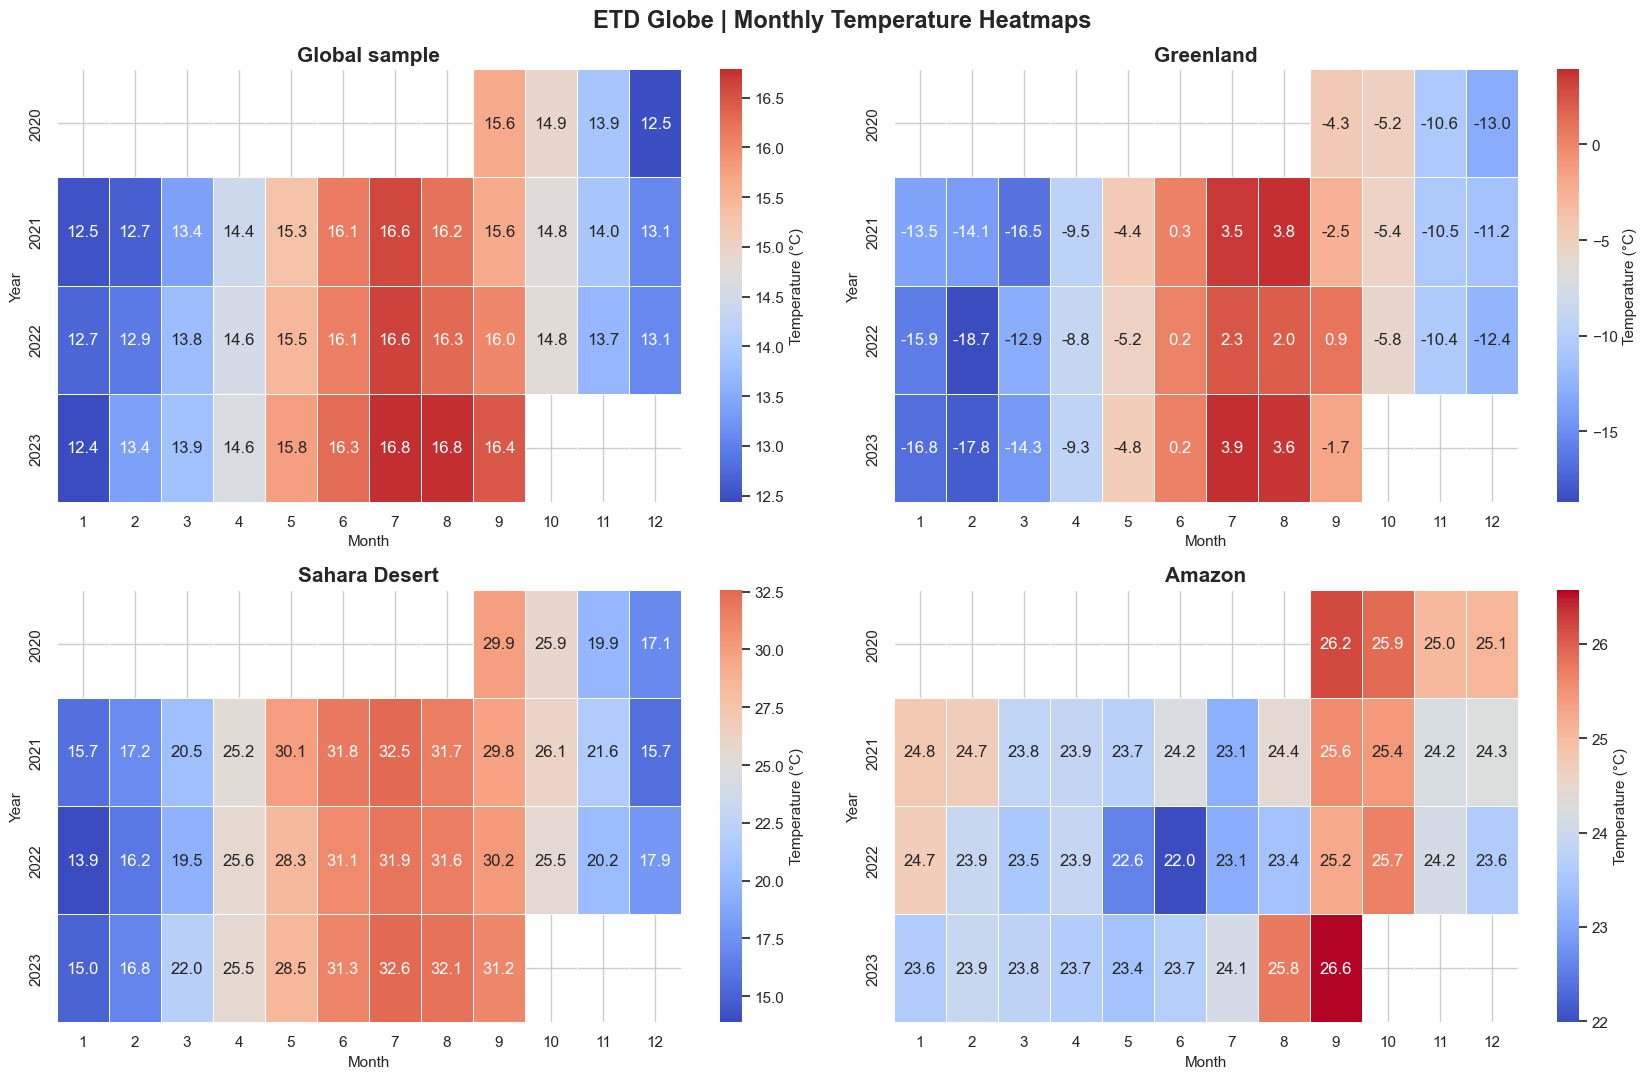

In [38]:
heatmap_series = {
    "Global sample": global_monthly,
    **region_monthly
}

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
axes = axes.flatten()

for ax, (name, monthly_df) in zip(axes, heatmap_series.items()):
    heatmap_data = monthly_df.pivot_table(
        index="year",
        columns="month",
        values="T2M_mean_C",
        aggfunc="mean"
    )

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".1f",
        cmap="coolwarm",
        center=heatmap_data.stack().mean(),
        linewidths=0.5,
        ax=ax,
        cbar_kws={"label": "Temperature (°C)"}
    )
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Month")
    ax.set_ylabel("Year")

plt.suptitle(
    "ETD Globe | Monthly Temperature Heatmaps",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

**Thanks for your attention :))**